# VoxLens EDA — Amazon_Fashion + All_Beauty
PRD Phase 1 exploratory analysis on cleaned reviews (`data/processed/reviews.parquet`).
All numbers below are produced by running this notebook; re-run via `make eda`.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
root = Path("..") if Path("data/processed").exists() is False else Path(".")
# Notebook may run from notebooks/ or repo root
if not (root / "data/processed/reviews.parquet").exists():
    root = Path("..")
df = pd.read_parquet(root / "data/processed/reviews.parquet")
print(f"rows={len(df):,} cols={list(df.columns)}")
df.head(3)

rows=3,024,584 cols=['review_id', 'product_id', 'category', 'rating', 'label', 'title', 'text', 'clean_text', 'reviewed_at', 'split']


,review_id,product_id,category,rating,label,title,text,clean_text,reviewed_at,split
0,30b5756f6e3d111dd3766f0841206b5c,B00YQ6X8EO,All_Beauty,5,positive,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,This spray is really nice. It smells really go...,2020-05-05 14:08:48.923+00:00,val
1,1c556cc530188919d6bfce9920aee75a,B081TJ8YS3,All_Beauty,4,positive,Works great but smells a little weird.,"This product does what I need it to do, I just...","This product does what I need it to do, I just...",2020-05-04 18:10:55.070+00:00,train
2,a0a27a5bba7b5f4f993e31d74cbc827c,B097R46CSY,All_Beauty,5,positive,Yes!,"Smells good, feels great!","Smells good, feels great!",2020-05-16 21:41:06.052+00:00,train


In [2]:
df.info(memory_usage="deep")
print("\nnulls:")
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 3024584 entries, 0 to 3024583
Data columns (total 10 columns):
 #   Column       Dtype              
---  ------       -----              
 0   review_id    str                
 1   product_id   str                
 2   category     str                
 3   rating       int64              
 4   label        str                
 5   title        str                
 6   text         str                
 7   clean_text   str                
 8   reviewed_at  datetime64[us, UTC]
 9   split        str                
dtypes: datetime64[us, UTC](1), int64(1), str(8)
memory usage: 1.4 GB

nulls:
review_id      0
product_id     0
category       0
rating         0
label          0
title          0
text           0
clean_text     0
reviewed_at    0
split          0
dtype: int64


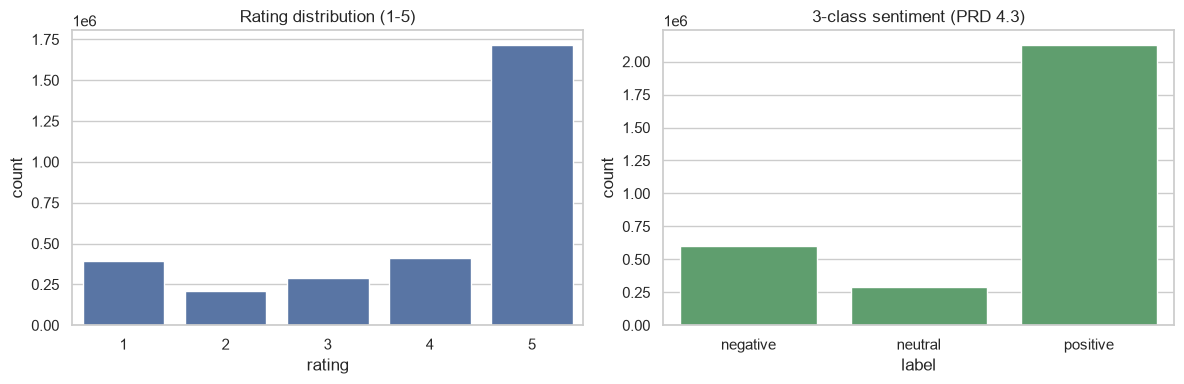

label
positive    0.7042
negative    0.1994
neutral     0.0964


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = [1, 2, 3, 4, 5]
sns.countplot(x="rating", data=df, order=order, ax=axes[0], color="#4C72B0")
axes[0].set_title("Rating distribution (1-5)")
label_order = ["negative", "neutral", "positive"]
sns.countplot(x="label", data=df, order=label_order, ax=axes[1], color="#55A868")
axes[1].set_title("3-class sentiment (PRD 4.3)")
plt.tight_layout()
plt.show()
print(df["label"].value_counts(normalize=True).round(4).to_string())

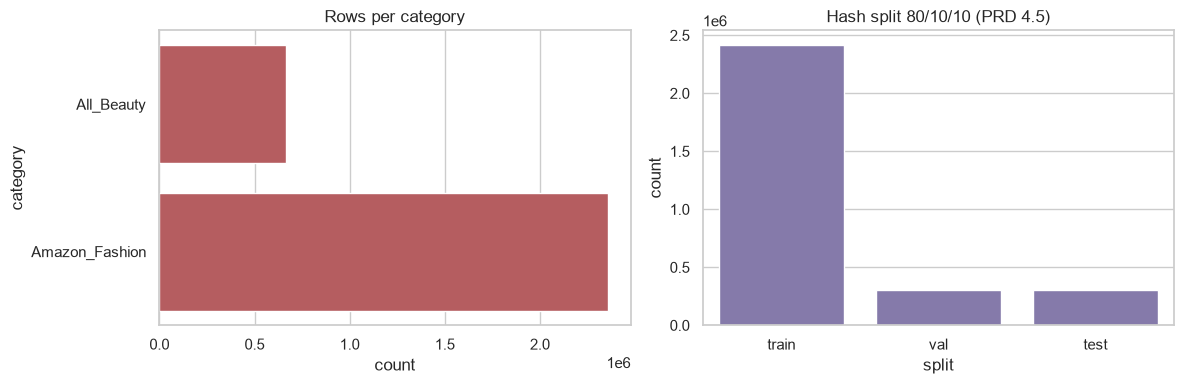

label  negative  neutral  positive
split                             
test      60585    29034    212626
train    482270   233509   1704464
val       60281    29045    212770


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(y="category", data=df, ax=axes[0], color="#C44E52")
axes[0].set_title("Rows per category")
sns.countplot(x="split", data=df, order=["train", "val", "test"], ax=axes[1], color="#8172B2")
axes[1].set_title("Hash split 80/10/10 (PRD 4.5)")
plt.tight_layout()
plt.show()
print(df.groupby(["split", "label"]).size().unstack(fill_value=0))

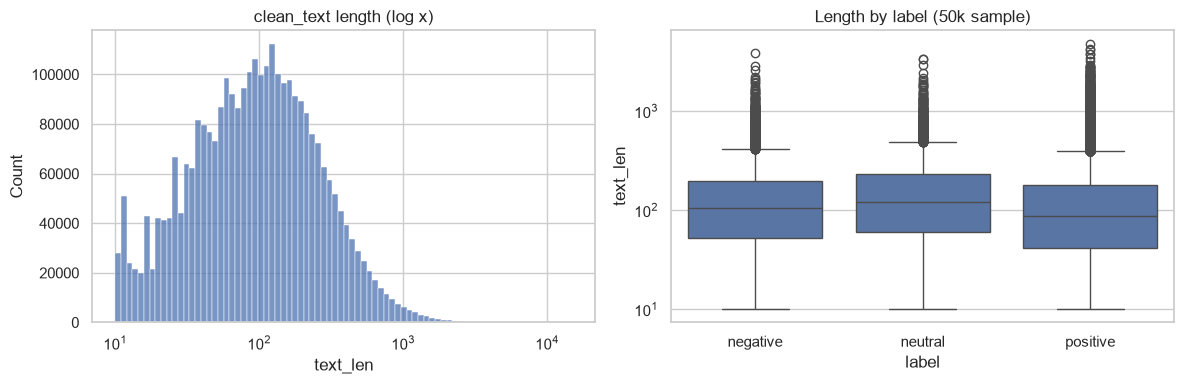

              count   mean    std   min   25%    50%    75%      max
label                                                               
negative   603136.0  157.1  180.4  10.0  53.0  106.0  198.0  12780.0
neutral    291588.0  180.9  217.5  10.0  60.0  120.0  225.0  14917.0
positive  2129860.0  150.0  204.4  10.0  41.0   89.0  181.0  10565.0


In [5]:
df["text_len"] = df["clean_text"].str.len()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["text_len"], bins=80, ax=axes[0], log_scale=(True, False))
axes[0].set_title("clean_text length (log x)")
sns.boxplot(x="label", y="text_len", data=df.sample(50_000, random_state=42), order=label_order, ax=axes[1])
axes[1].set_title("Length by label (50k sample)")
axes[1].set_yscale("log")
plt.tight_layout()
plt.show()
print(df.groupby("label")["text_len"].describe().round(1))

In [6]:
# Integrity: unique review_ids, no null labels, min length >= 10
assert df["review_id"].is_unique
assert df["label"].notna().all()
assert df["clean_text"].str.len().min() >= 10
assert set(df["split"]) <= {"train", "val", "test"}
print("integrity checks passed")
print("label x category:")
print(pd.crosstab(df["category"], df["label"]))

integrity checks passed
label x category:


label           negative  neutral  positive
category                                   
All_Beauty        141001    54389    471074
Amazon_Fashion    462135   237199   1658786


In [7]:
# Sample reviews per label (truncated)
for label in label_order:
    print(f"--- {label} ---")
    for t in df.loc[df["label"] == label, "clean_text"].head(2):
        print(t[:220].replace("\n", " "), "...")
        print()

--- negative ---
Felt synthetic ...

nothing special unfortunately i waited too long to return them .... no results at all dont waste your money ...

--- neutral ---


These were lightweight and soft but much too small for my liking. I would have preferred two of these together to make one loc. For that reason I will not be repurchasing. ...

I was very disappointed when I got this facial scrub. I had assumed it was like other scrubs I use but it wasn't. This is a powder which you need to mix with water to make a paste before you put it on your face. I have a ...

--- positive ---
This spray is really nice. It smells really good, goes on really fine, and does the trick. I will say it feels like you need a lot of it though to get the texture I want. I have a lot of hair, medium thickness. I am comp ...

This product does what I need it to do, I just wish it was odorless or had a soft coconut smell. Having my head smell like an orange coffee is offputting. (granted, I did know the smell was described but I was hoping it  ...



## Findings
- Positive reviews dominate (expected class imbalance, PRD 4.7) — macro-F1 is the headline metric.
- Neutral (3-star) is the noisiest class and must be discussed in analysis (PRD 4.3).
- Split proportions are ~80/10/10 by construction of the hash bucketing.
- All numbers above are regenerated by `make eda`; none are hard-coded.